<a href="https://colab.research.google.com/github/navyabhatnagar2024/CodeQuest/blob/main/Online_shoppers_purchasing_intention_ml_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("online_shoppers_intention (1).csv")

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
print("Number of sessions:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of sessions: 12330
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   123

In [ ]:
print("Missing values per column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values per column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Number of duplicate rows:
125


In [ ]:
print("Number of sessions in each group:")
print(df["Revenue"].value_counts())

print("\nPercentage of sessions in each group:")
print((df["Revenue"].value_counts(normalize=True) * 100).round(2))

Number of sessions in each group:
Revenue
False    10422
True      1908
Name: count, dtype: int64

Percentage of sessions in each group:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


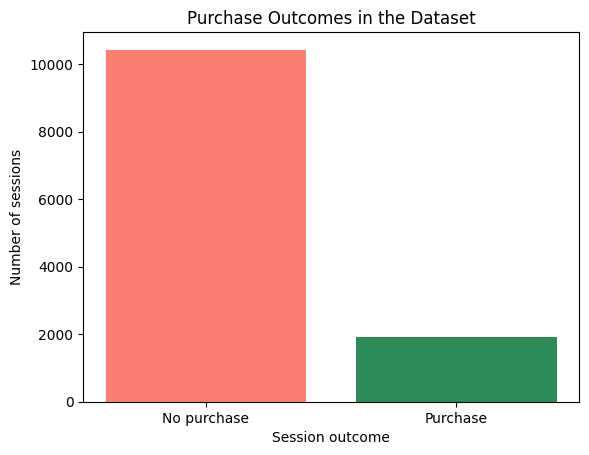

In [ ]:
import matplotlib.pyplot as plt

counts = df["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

plt.bar(
    ["No purchase", "Purchase"],
    counts.values,
    color=["salmon", "seagreen"]
)

plt.title("Purchase Outcomes in the Dataset")
plt.xlabel("Session outcome")
plt.ylabel("Number of sessions")
plt.show()

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Remaining rows:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Remaining rows: 12205
Remaining duplicates: 0


Organizing the data for training and testing

we are dividing the data into two columns X and y, where X contains the data and y contains its outcomes.
They both will be used in Training and Testing the model.

In [ ]:
X = df.drop(columns=["Revenue", "PageValues"])
y = df["Revenue"]

print("Number of input columns:", X.shape[1])
print("Inputs:", X.columns.tolist())

Number of input columns: 16
Inputs: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']


Splitting the data into training and testing data

Training Data : 80%
Testing Data : 20%

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training sessions:", len(X_train))
print("Testing sessions:", len(X_test))

Training sessions: 9764
Testing sessions: 2441


- X_train: Browsing details for training.
- y_train: Correct answers for those training sessions.
- X_test: Browsing details for testing.
- y_test: Correct answers for those testing sessions.

1. Specify which columns are categories

Preparing the inputs so the model can understand them. We’ll convert categories into numbers and put numerical values on a similar scale.

In [ ]:
categorical_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_columns = [
    column for column in X_train.columns
    if column not in categorical_columns
]

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']


2.Create the preprocessing instructions

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns),

        ("numbers", StandardScaler(),
         numerical_columns)
    ]
)

Training the model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Testing the model

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
comparison = pd.DataFrame({
    "Actual outcome": y_test.to_numpy(),
    "Predicted outcome": y_pred
})

comparison["Correct?"] = (
    comparison["Actual outcome"] == comparison["Predicted outcome"]
)

comparison.head(10)

,Actual outcome,Predicted outcome,Correct?
0,False,True,False
1,False,True,False
2,False,True,False
3,False,False,True
4,False,False,True
5,False,True,False
6,False,False,True
7,False,False,True
8,False,True,False
9,False,False,True


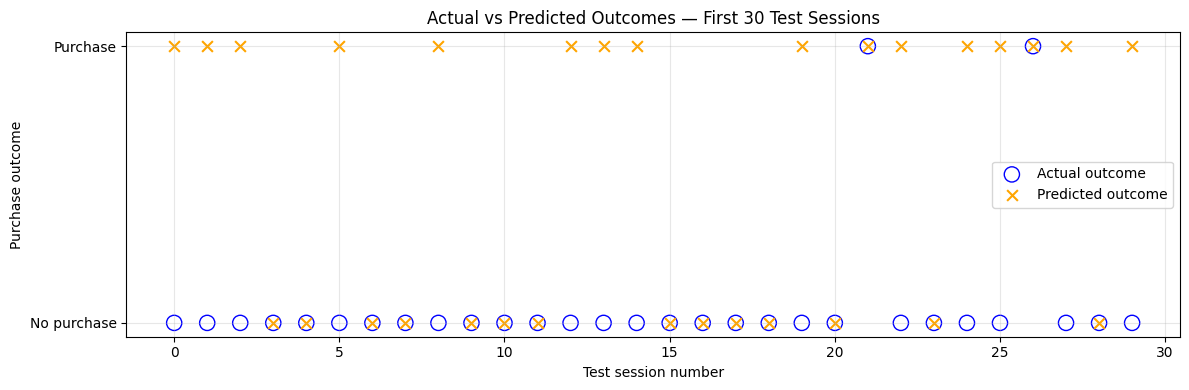

In [ ]:
import matplotlib.pyplot as plt

# Use a small sample so the plot stays readable
sample = comparison.head(30)

# Convert False to 0 and True to 1 for plotting
actual = sample["Actual outcome"].astype(int)
predicted = sample["Predicted outcome"].astype(int)

plt.figure(figsize=(12, 4))

plt.scatter(
    sample.index, actual,
    label="Actual outcome",
    marker="o", s=120,
    facecolors="none", edgecolors="blue"
)

plt.scatter(
    sample.index, predicted,
    label="Predicted outcome",
    marker="x", s=60, color="orange"
)

plt.yticks([0, 1], ["No purchase", "Purchase"])
plt.xlabel("Test session number")
plt.ylabel("Purchase outcome")
plt.title("Actual vs Predicted Outcomes — First 30 Test Sessions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.2%}")

Test accuracy: 64.93%


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

              precision    recall  f1-score   support

 No purchase       0.94      0.62      0.75      2059
    Purchase       0.28      0.78      0.41       382

    accuracy                           0.65      2441
   macro avg       0.61      0.70      0.58      2441
weighted avg       0.84      0.65      0.70      2441



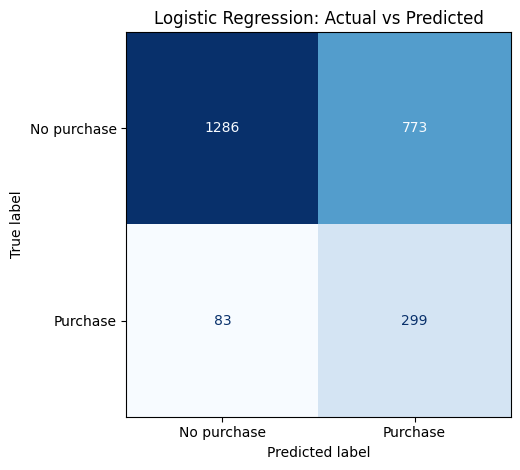

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No purchase", "Purchase"],
    cmap="Blues",
    colorbar=False
)

plt.title("Logistic Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": model,
    "Random Forest": rf_model
}

for name, candidate in models.items():
    scores = cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )

    print(f"{name}: Average purchase F1 = {scores.mean():.3f}")

Logistic Regression: Average purchase F1 = 0.391
Random Forest: Average purchase F1 = 0.106


In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Create four model configurations
candidates = {
    "Logistic — balanced": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Logistic — default": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "Forest — balanced": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Forest — default": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Use the same five splits for every model
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Train and evaluate within the training data
for name, candidate in candidates.items():
    results = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "purchase_f1": "f1"
        }
    )

    print(name)
    print(f"  Average accuracy: {results['test_accuracy'].mean():.2%}")
    print(f"  Average purchase F1: {results['test_purchase_f1'].mean():.3f}")
    print()

Logistic — balanced
  Average accuracy: 64.29%
  Average purchase F1: 0.391

Logistic — default
  Average accuracy: 84.32%
  Average purchase F1: 0.060

Forest — balanced
  Average accuracy: 83.52%
  Average purchase F1: 0.313

Forest — default
  Average accuracy: 84.67%
  Average purchase F1: 0.106



So Logistic Regression catches many buyers, but gives too many false purchase alerts. Random Forest performed worse by purchase F1 in our comparison. We need its precision and recall to explain its particular mistakes.

Balanced Logistic Regression is the best of these four at identifying purchases, based on purchase F1.

In [ ]:
import pandas as pd

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Upload and load the CSV
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

# 2. Remove identical duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# 3. Separate inputs and answers
X = df.drop(columns=["Revenue", "PageValues"])
y = df["Revenue"]

# 4. Create training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Identify categorical and numerical columns
categorical_columns = [
    "Month", "OperatingSystems", "Browser",
    "Region", "TrafficType", "VisitorType", "Weekend"
]

numerical_columns = [
    column for column in X_train.columns
    if column not in categorical_columns
]

# 6. Create preprocessing instructions
preprocessor = ColumnTransformer([
    ("categories",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_columns),

    ("numbers",
     StandardScaler(),
     numerical_columns)
])

# 7. Create and train the selected model
final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

final_model.fit(X_train, y_train)

# 8. Evaluate on testing data
final_predictions = final_model.predict(X_test)

print("\nModel training completed!")
print(f"Test accuracy: {accuracy_score(y_test, final_predictions):.2%}")

print(classification_report(
    y_test,
    final_predictions,
    labels=[False, True],
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

Saving online_shoppers_intention.csv to online_shoppers_intention.csv

Model training completed!
Test accuracy: 64.93%
              precision    recall  f1-score   support

 No purchase       0.94      0.62      0.75      2059
    Purchase       0.28      0.78      0.41       382

    accuracy                           0.65      2441
   macro avg       0.61      0.70      0.58      2441
weighted avg       0.84      0.65      0.70      2441



In [ ]:
import joblib
from google.colab import files

joblib.dump(final_model, "shopper_purchase_model.joblib")

files.download("shopper_purchase_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
from google.colab import files

uploaded = files.upload()  # Choose your saved .joblib file
filename = next(iter(uploaded))

final_model = joblib.load(filename)

print("Trained model loaded!")

Saving shopper_purchase_model.joblib to shopper_purchase_model (1).joblib
Trained model loaded!


In [ ]:
# Select 10 test sessions
sample_sessions = X_test.head(10)

# Predict their purchase outcomes
predictions = final_model.predict(sample_sessions)

# Compare predictions with actual outcomes
demo = sample_sessions.copy()

demo["Actual purchase"] = y_test.loc[sample_sessions.index]
demo["Predicted purchase"] = predictions
demo["Correct prediction"] = (
    demo["Actual purchase"] == demo["Predicted purchase"]
)

# Display a few inputs alongside the results
demo[[
    "ProductRelated",
    "ProductRelated_Duration",
    "VisitorType",
    "Actual purchase",
    "Predicted purchase",
    "Correct prediction"
]]

,ProductRelated,ProductRelated_Duration,VisitorType,Actual purchase,Predicted purchase,Correct prediction
11640,12,482.500000,Returning_Visitor,False,True,False
6936,16,473.283333,New_Visitor,False,True,False
7194,29,2107.033333,Returning_Visitor,False,True,False
11263,11,329.683333,Returning_Visitor,False,False,True
4728,5,0.000000,Returning_Visitor,False,False,True
9878,169,8276.292565,Returning_Visitor,False,True,False
8101,5,1377.250000,Returning_Visitor,False,False,True
6642,89,2577.960349,Returning_Visitor,False,False,True
10215,2,180.147059,Returning_Visitor,False,True,False
10224,6,161.666667,New_Visitor,False,False,True


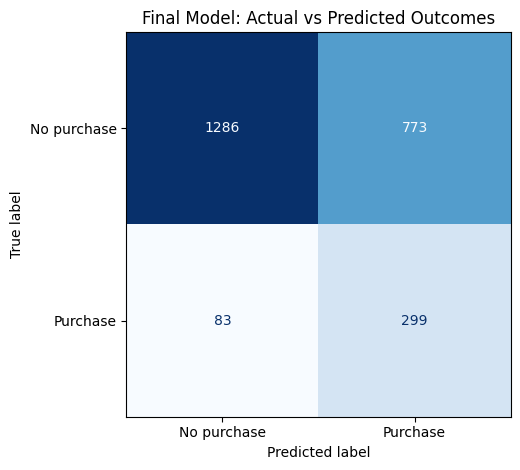

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

final_predictions = final_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=[False, True],
    display_labels=["No purchase", "Purchase"],
    cmap="Blues",
    colorbar=False
)

plt.title("Final Model: Actual vs Predicted Outcomes")
plt.tight_layout()
plt.show()

current 28% purchase precision means too many false purchase alerts.
The next improvement should be adjusting the prediction threshold using training-data cross-validation. Currently, the model predicts purchase when its score reaches 0.5. A higher threshold may reduce false alerts, though it will also miss more buyers.


If we raise the cutoff to 0.7, the model becomes more selective in predicting purchases and non purchases.

Currently, the model predicts too many puchases even when there is no purchase.
model currently predicts “Purchase” too often. Raising the cutoff can reduce those false alerts, but some actual buyers may also fall below the new cutoff and be missed.
We’ll compare different cutoffs to see which gives a useful balance. This changes how we turn the model’s score into a decision; it doesn’t teach the model new patterns.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report

# Set up five training/validation rounds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate purchase scores for the training sessions
# Each session is scored by a model that didn't train on it
cv_scores = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Apply the new cutoff
threshold = 0.7
cv_predictions = cv_scores >= threshold

# Display performance
print(f"Threshold: {threshold}")
print(
    f"Cross-validation accuracy: "
    f"{accuracy_score(y_train, cv_predictions):.2%}"
)

print(classification_report(
    y_train,
    cv_predictions,
    labels=[False, True],
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

Threshold: 0.7
Cross-validation accuracy: 80.35%
              precision    recall  f1-score   support

 No purchase       0.88      0.89      0.88      8238
    Purchase       0.36      0.32      0.34      1526

    accuracy                           0.80      9764
   macro avg       0.62      0.61      0.61      9764
weighted avg       0.79      0.80      0.80      9764



Goal of the model : at least 80% purchase precision, while finding as many actual buyers as possible.

The model should have high precision and recall, so the store's recommender system can actually provide the buyers what they need to make their purchase more efficient and convenient

Purchase precision ≥ 80%
High purchase recall

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score

rows = []

for cutoff in np.arange(0.05, 1.00, 0.01):
    predictions = cv_scores >= cutoff

    rows.append({
        "Cutoff": round(float(cutoff), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "Predicted buyers": int(predictions.sum())
    })

results = pd.DataFrame(rows)

eligible = results[
    (results["Precision"] >= 0.80) &
    (results["Predicted buyers"] > 0)
].sort_values("Recall", ascending=False)

if eligible.empty:
    print("This model did not reach 80% precision at the tested cutoffs.")
else:
    print("Cutoffs reaching at least 80% precision:")
    print(eligible.head(10).round(3).to_string(index=False))

This model did not reach 80% precision at the tested cutoffs.


Raising the cutoff alone isn’t enough—we need to test a model that learns more complex patterns.

Trying Gradient Boosting

It builds small decision trees sequentially, with later trees correcting earlier mistakes. Improvement isn’t guaranteed; we’ll measure it using the same training-data cross-validation.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Create a new model with the same preprocessing
boost_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Score sessions without training on those same sessions
boost_scores = cross_val_predict(
    boost_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Compare prediction cutoffs
rows = []

for cutoff in np.arange(0.05, 1.00, 0.01):
    predictions = boost_scores >= cutoff

    rows.append({
        "Cutoff": round(float(cutoff), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Predicted buyers": int(predictions.sum())
    })

boost_results = pd.DataFrame(rows)

eligible = boost_results[
    (boost_results["Precision"] >= 0.80) &
    (boost_results["Predicted buyers"] > 0)
].sort_values("Recall", ascending=False)

if eligible.empty:
    print("Gradient Boosting did not reach 80% precision.")
    print("\nIts five highest-F1 cutoffs:")
    print(
        boost_results.sort_values("F1", ascending=False)
        .head(5).round(3).to_string(index=False)
    )
else:
    print("Cutoffs reaching at least 80% precision:")
    print(eligible.head(5).round(3).to_string(index=False))

Gradient Boosting did not reach 80% precision.

Its five highest-F1 cutoffs:
 Cutoff  Precision  Recall    F1  Predicted buyers
   0.21      0.334   0.585 0.425              2673
   0.22      0.343   0.554 0.423              2470
   0.20      0.322   0.615 0.422              2915
   0.19      0.312   0.645 0.420              3158
   0.23      0.349   0.520 0.418              2275


Gradient Boosting improved the precision–recall balance slightly, but it still falls well short of the goal of precision >= 80%

At cutoff 0.21:
- Precision: 33.4% — about 33 of every 100 predicted buyers actually bought.
- Recall: 58.5% — it identifies about 59 of every 100 actual buyers.
- F1: 0.425 — slightly higher than Logistic Regression’s roughly 0.39.

In [ ]:
print("Training input shape:", X_train.shape)
print("Training answer shape:", y_train.shape)

print("\nInput columns:")
print(X_train.columns.tolist())

print("\nDo input and answer row indexes match?")
print(X_train.index.equals(y_train.index))

print("\nPurchase outcomes:")
print(y_train.value_counts())

print("\nColumns used by preprocessing:")
print("Categorical:", categorical_columns)
print("Numerical:", numerical_columns)

print("\nHighest-precision Gradient Boosting cutoffs:")
print(
    boost_results[boost_results["Predicted buyers"] >= 100]
    .sort_values(
        ["Precision", "Recall"],
        ascending=False
    )
    .head(5)
    .round(3)
    .to_string(index=False)
)

Training input shape: (9764, 16)
Training answer shape: (9764,)

Input columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Do input and answer row indexes match?
True

Purchase outcomes:
Revenue
False    8238
True     1526
Name: count, dtype: int64

Columns used by preprocessing:
Categorical: ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay']

Highest-precision Gradient Boosting cutoffs:
 Cutoff  Precision  Recall    F1  Predicted buyers
   0.53      0.538   0.037 0.069               104
   0.52      0.529   0.042 0.078               121
   

inputs and answers have matching row indexes, and preprocessing covers all inputs.
But the model still struggles:
- At cutoff 0.53, precision reaches 53.8%, but recall is only 3.7%.
- That means it identifies fewer than 4 out of every 100 actual buyers.
We should stop raising the cutoff—it isn’t solving the underlying problem.

In [ ]:
# Check ranges and variation in numerical inputs
print(X_train[numerical_columns].describe().T)

# Check whether labels still match the source table
print(
    "\nLabels match original rows:",
    y_train.equals(df.loc[X_train.index, "Revenue"])
)

# Compare browsing behaviour for buyers and non-buyers
check = X_train.copy()
check["Revenue"] = y_train

print("\nMedian browsing values by purchase outcome:")
print(
    check.groupby("Revenue")[
        [
            "ProductRelated",
            "ProductRelated_Duration",
            "BounceRates",
            "ExitRates"
        ]
    ].median()
)

                          count         mean          std  min         25%  \
Administrative           9764.0     2.342687     3.349268  0.0    0.000000   
Administrative_Duration  9764.0    82.219938   179.502363  0.0    0.000000   
Informational            9764.0     0.510344     1.282728  0.0    0.000000   
Informational_Duration   9764.0    34.950623   143.828323  0.0    0.000000   
ProductRelated           9764.0    32.101803    44.817312  0.0    8.000000   
ProductRelated_Duration  9764.0  1207.264687  1926.389159  0.0  193.466667   
BounceRates              9764.0     0.020296     0.045234  0.0    0.000000   
ExitRates                9764.0     0.041469     0.046145  0.0    0.014286   
SpecialDay               9764.0     0.062351     0.199959  0.0    0.000000   

                                50%          75%          max  
Administrative             1.000000     4.000000     27.00000  
Administrative_Duration    9.000000    94.725000   3398.75000  
Informational              

it compares buyers’ browsing behaviour with non-buyers’ behaviour

We conclude from the onbservation that in this training data, buyers typically viewed more product pages than non-buyers

In [ ]:
check = X_train.copy()
check["Revenue"] = y_train

visitor_summary = check.groupby("VisitorType")["Revenue"].agg(
    Sessions="size",
    Purchases="sum",
    Purchase_rate="mean"
)

visitor_summary["Purchase_rate"] *= 100

print(visitor_summary.round(2))

                   Sessions  Purchases  Purchase_rate
VisitorType                                          
New_Visitor            1349        325          24.09
Other                    68         16          23.53
Returning_Visitor      8347       1185          14.20


- New visitors buy more often proportionally: about 24 purchases per 100 sessions, compared with 14 for returning visitors.
- Returning visitors contribute more purchases overall: 1,185, because they account for far more sessions.

Our next goal is still: reach at least 80% purchase precision while identifying as many buyers as possible.

In [ ]:
# Check numerical values
print("Numerical data summary:")
print(X_train[numerical_columns].describe().T)

# Verify the answers match the original dataset
print(
    "\nLabels match original rows:",
    y_train.equals(df.loc[X_train.index, "Revenue"])
)

# Compare buyers and non-buyers
check = X_train.copy()
check["Revenue"] = y_train

print("\nMedian browsing behaviour:")
print(
    check.groupby("Revenue")[
        [
            "ProductRelated",
            "ProductRelated_Duration",
            "BounceRates",
            "ExitRates"
        ]
    ].median()
)

Numerical data summary:
                          count         mean          std  min         25%  \
Administrative           9764.0     2.342687     3.349268  0.0    0.000000   
Administrative_Duration  9764.0    82.219938   179.502363  0.0    0.000000   
Informational            9764.0     0.510344     1.282728  0.0    0.000000   
Informational_Duration   9764.0    34.950623   143.828323  0.0    0.000000   
ProductRelated           9764.0    32.101803    44.817312  0.0    8.000000   
ProductRelated_Duration  9764.0  1207.264687  1926.389159  0.0  193.466667   
BounceRates              9764.0     0.020296     0.045234  0.0    0.000000   
ExitRates                9764.0     0.041469     0.046145  0.0    0.014286   
SpecialDay               9764.0     0.062351     0.199959  0.0    0.000000   

                                50%          75%          max  
Administrative             1.000000     4.000000     27.00000  
Administrative_Duration    9.000000    94.725000   3398.75000  
Inf

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Make a copy; preserve the original training inputs
X_train_extra = X_train.copy()

# 2. Add average time per product page
page_count = X_train_extra["ProductRelated"].replace(0, np.nan)

X_train_extra["TimePerProductPage"] = (
    X_train_extra["ProductRelated_Duration"] / page_count
).fillna(0)

# 3. Include the new numerical column in preprocessing
extra_numerical_columns = numerical_columns + ["TimePerProductPage"]

extra_preprocessor = ColumnTransformer([
    ("categories",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_columns),

    ("numbers",
     StandardScaler(),
     extra_numerical_columns)
])

# 4. Use the same Gradient Boosting settings for a fair comparison
extra_model = clone(boost_model)
extra_model.set_params(preprocessing=extra_preprocessor)

# 5. Generate cross-validation scores
extra_scores = cross_val_predict(
    extra_model,
    X_train_extra,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# 6. Evaluate different cutoffs
rows = []

for cutoff in np.arange(0.05, 1.00, 0.01):
    predictions = extra_scores >= cutoff

    rows.append({
        "Cutoff": round(float(cutoff), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Predicted buyers": int(predictions.sum())
    })

extra_results = pd.DataFrame(rows)

print("Five highest-F1 cutoffs:")
print(
    extra_results.sort_values("F1", ascending=False)
    .head(5).round(3).to_string(index=False)
)

eligible = extra_results[
    (extra_results["Precision"] >= 0.80) &
    (extra_results["Predicted buyers"] > 0)
].sort_values("Recall", ascending=False)

print("\nCutoffs reaching 80% precision:")
if eligible.empty:
    print("None reached the target.")
else:
    print(eligible.head(5).round(3).to_string(index=False))

Five highest-F1 cutoffs:
 Cutoff  Precision  Recall    F1  Predicted buyers
   0.20      0.328   0.622 0.429              2896
   0.21      0.336   0.591 0.428              2685
   0.19      0.318   0.655 0.428              3141
   0.22      0.345   0.562 0.427              2490
   0.24      0.363   0.509 0.424              2136

Cutoffs reaching 80% precision:
 Cutoff  Precision  Recall    F1  Predicted buyers
   0.69        1.0   0.002 0.004                 3
   0.70        1.0   0.001 0.001                 1
   0.71        1.0   0.001 0.001                 1
   0.72        1.0   0.001 0.001                 1
   0.73        1.0   0.001 0.001                 1


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Use our model with the extra time-per-page feature
tuning_model = clone(extra_model)

# Try 2 × 2 × 2 = 8 combinations
settings = {
    "classifier__n_estimators": [150, 300],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_leaf": [10, 30]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=tuning_model,
    param_grid=settings,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

search.fit(X_train_extra, y_train)

print("Best settings:", search.best_params_)
print(
    "Best cross-validation average precision:",
    round(search.best_score_, 3)
)

tuned_model = search.best_estimator_

Best settings: {'classifier__max_depth': 2, 'classifier__min_samples_leaf': 30, 'classifier__n_estimators': 300}
Best cross-validation average precision: 0.364


test the eight combinations:
HyperParameter Tuning

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold

tuning_model = clone(extra_model)

settings = {
    "classifier__n_estimators": [150, 300],
    "classifier__max_depth": [2, 3],
    "classifier__min_samples_leaf": [10, 30]
}

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=tuning_model,
    param_grid=settings,
    scoring="average_precision",
    cv=tuning_cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

search.fit(X_train_extra, y_train)

tuned_model = search.best_estimator_

print("\nBest settings:")
print(search.best_params_)

print(
    "\nBest cross-validation average precision:",
    round(search.best_score_, 3)
)

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best settings:
{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 30, 'classifier__n_estimators': 300}

Best cross-validation average precision: 0.364


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score

validation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuned_scores = cross_val_predict(
    tuned_model,
    X_train_extra,
    y_train,
    cv=validation_cv,
    method="predict_proba"
)[:, 1]

rows = []

for cutoff in np.arange(0.05, 1.00, 0.01):
    predictions = tuned_scores >= cutoff

    rows.append({
        "Cutoff": round(float(cutoff), 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "Predicted buyers": int(predictions.sum())
    })

tuned_results = pd.DataFrame(rows)

# Inspect cutoffs with a reasonable number of predictions
substantial = tuned_results[
    tuned_results["Predicted buyers"] >= 100
]

print("Highest-precision cutoffs predicting at least 100 buyers:")
print(
    substantial.sort_values(
        ["Precision", "Recall"], ascending=False
    ).head(5).round(3).to_string(index=False)
)

Highest-precision cutoffs predicting at least 100 buyers:
 Cutoff  Precision  Recall  Predicted buyers
   0.53      0.546   0.039               108
   0.51      0.527   0.051               148
   0.52      0.523   0.045               130
   0.46      0.508   0.100               301
   0.45      0.506   0.112               338
